# Forecasting del prezzo NVIDIA

## Confronto tra baseline, ARIMA, ARIMAX e verifica stagionale

Il notebook valuta previsioni **giornaliere con aggiornamento progressivo** sulle ultime 30 giornate di borsa.

- La baseline naïve usa il prezzo osservato nella seduta precedente.
- ARIMA usa esclusivamente la storia del prezzo.
- ARIMAX usa come variabile esogena il log-volume della seduta precedente, già disponibile quando viene formulata la previsione. Il modello è stimato tramite la classe `SARIMAX` di statsmodels, senza componenti stagionali.
- Un vero SARIMAX con periodo di cinque sedute viene valutato separatamente, per verificare se una componente stagionale apporti un miglioramento.

Dopo ogni previsione, l'osservazione reale viene aggiunta alla storia prima di prevedere la seduta successiva. In questo modo non vengono utilizzate informazioni future.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import statsmodels.api as sm

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tools.sm_exceptions import ConvergenceWarning
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('always', category=ConvergenceWarning)

sns.set_theme(style='whitegrid', context='talk')
plt.rcParams.update({
    'figure.figsize': (14, 7),
    'figure.dpi': 110,
    'axes.titleweight': 'bold',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'legend.frameon': False,
})

DATA_PATH = Path('../data/raw/nvidia/NVDA.csv')
FIG_DIR = Path('figure_forecasting')
FIG_DIR.mkdir(exist_ok=True)

df = (
    pd.read_csv(DATA_PATH, parse_dates=['Date'])
      .sort_values('Date')
      .set_index('Date')
)

print(f'Osservazioni: {len(df):,}')
print(f'Periodo: {df.index.min().date()} — {df.index.max().date()}')
print(f'Valori mancanti: {int(df.isna().sum().sum())}')

Osservazioni: 6,558
Periodo: 1999-01-22 — 2025-02-14
Valori mancanti: 0


## 1. Esplorazione della serie

`Adj Close` viene utilizzato perché tiene conto delle operazioni societarie, come gli stock split. Il volume è mostrato in scala logaritmica per rendere leggibile l'intero periodo storico.

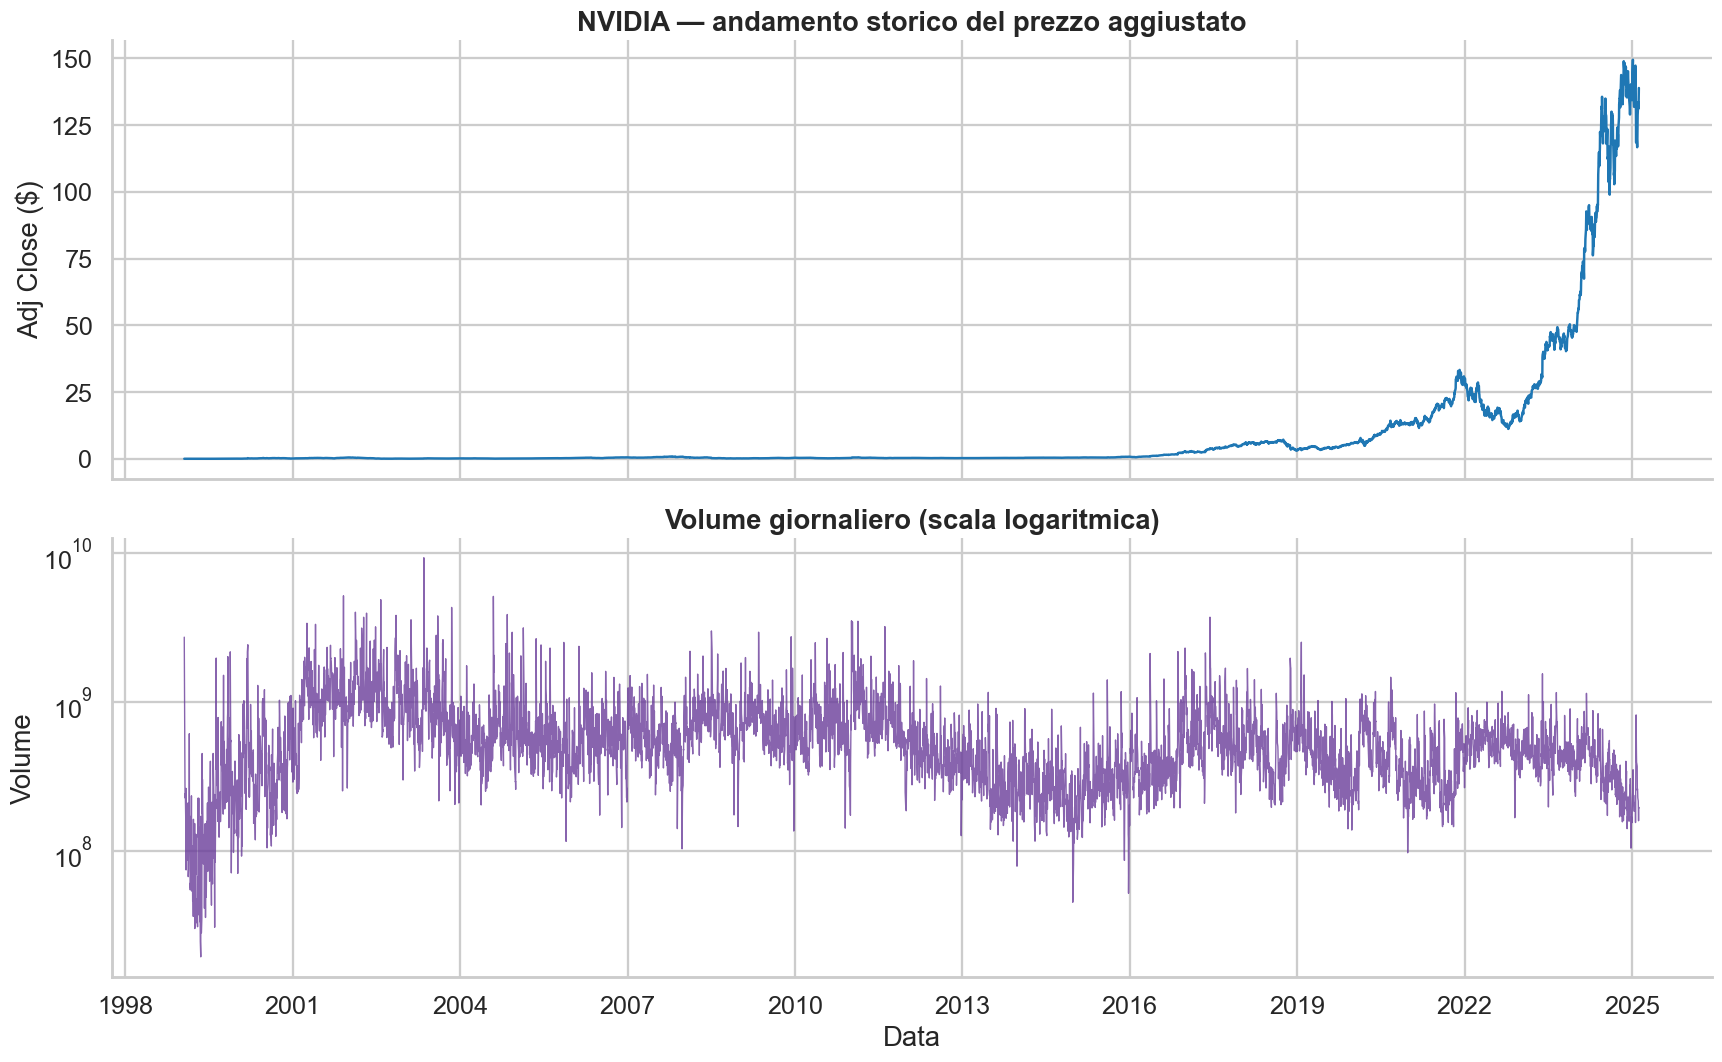

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

axes[0].plot(df.index, df['Adj Close'], color='#1f77b4', linewidth=1.6)
axes[0].set_title('NVIDIA — andamento storico del prezzo aggiustato')
axes[0].set_ylabel('Adj Close ($)')

axes[1].plot(df.index, df['Volume'], color='#6a3d9a', linewidth=0.9, alpha=0.8)
axes[1].set_yscale('log')
axes[1].set_title('Volume giornaliero (scala logaritmica)')
axes[1].set_ylabel('Volume')
axes[1].set_xlabel('Data')
axes[1].xaxis.set_major_locator(mdates.YearLocator(3))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

fig.tight_layout()
fig.savefig(FIG_DIR / '01_serie_storica.png', dpi=300, bbox_inches='tight')
plt.show()

## 2. Suddivisione temporale e stazionarietà

Prima delle verifiche utilizzate per costruire i modelli, le ultime 30 osservazioni vengono separate come test set. Test ADF, ACF, PACF e autocorrelazioni stagionali sono calcolati esclusivamente sul training set. La figura storica precedente rimane descrittiva e può mostrare l'intera serie.

,Serie,ADF statistic,p-value,Stazionaria al 5%
0,Log-prezzo — training,0.4257,9.8243e-01,False
1,Log-rendimento — training,-15.8204,1.0216e-28,True


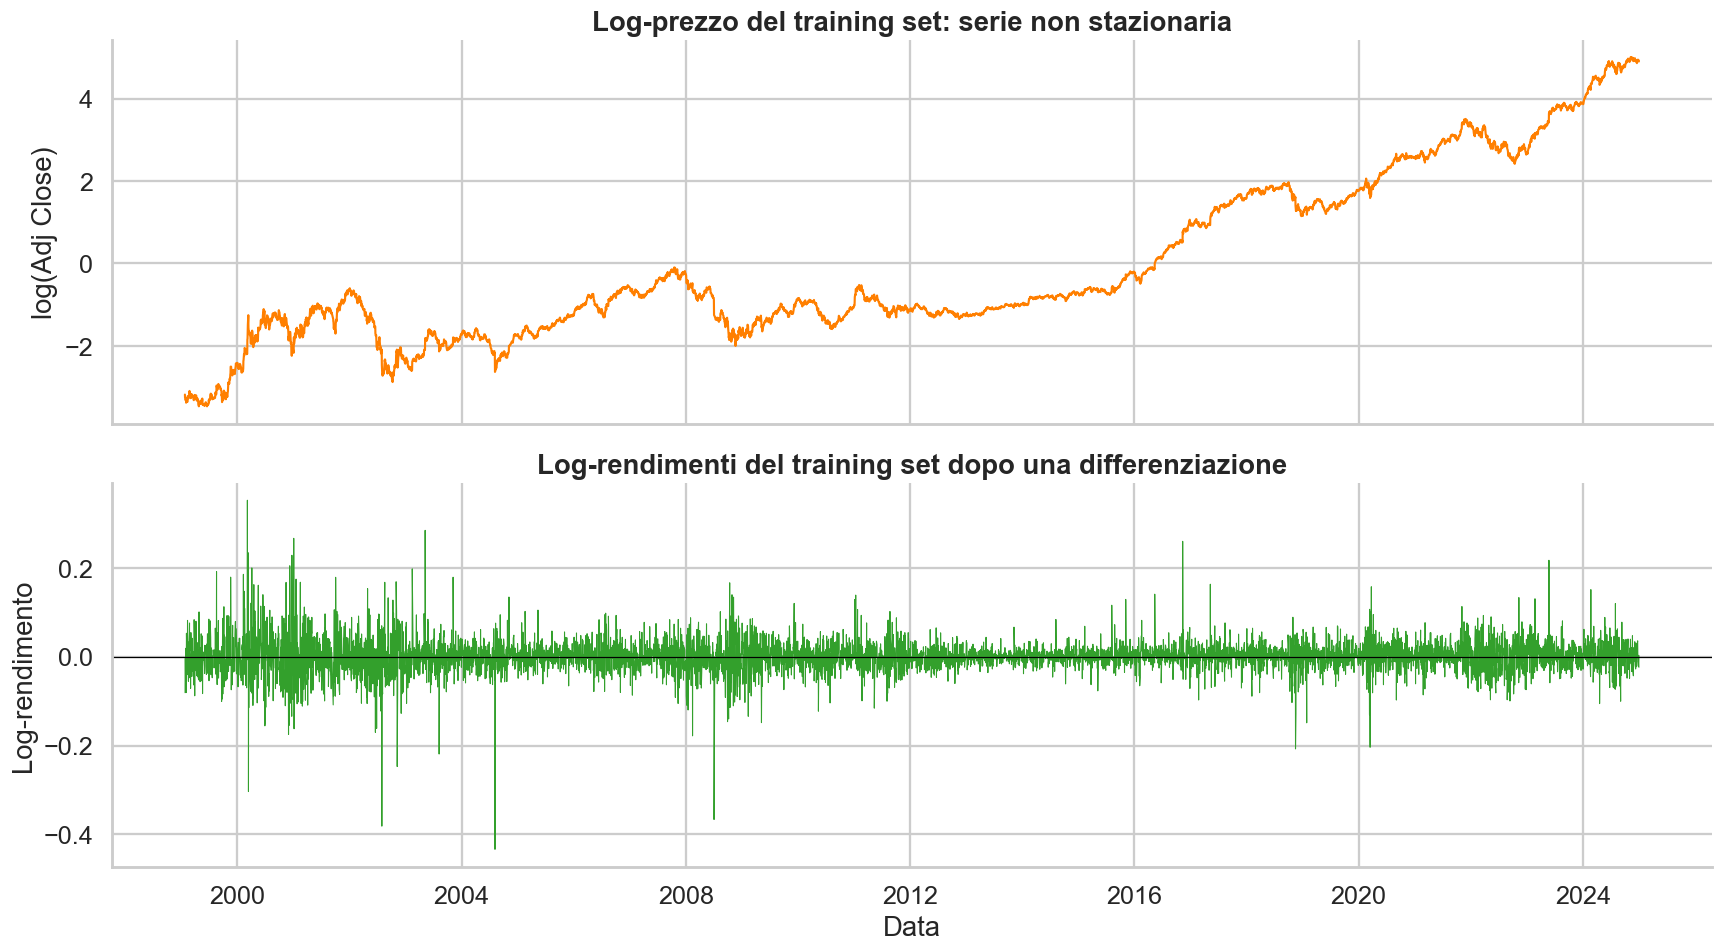

In [3]:
log_price = np.log(df['Adj Close'])
model_df = pd.DataFrame({
    'log_price': log_price,
    'log_volume_lag1': np.log(df['Volume']).shift(1),
}).dropna()

TEST_SIZE = 30
train = model_df.iloc[:-TEST_SIZE].copy()
test = model_df.iloc[-TEST_SIZE:].copy()
test_dates = test.index

train_log_price = train['log_price']
train_log_return = train_log_price.diff().dropna()

def adf_summary(series, name):
    result = adfuller(series.dropna())
    return {
        'Serie': name,
        'ADF statistic': result[0],
        'p-value': result[1],
        'Stazionaria al 5%': result[1] < 0.05,
    }

adf_table = pd.DataFrame([
    adf_summary(train_log_price, 'Log-prezzo — training'),
    adf_summary(train_log_return, 'Log-rendimento — training'),
])
display(adf_table.style.format({'ADF statistic': '{:.4f}', 'p-value': '{:.4e}'}))

fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)
axes[0].plot(train_log_price.index, train_log_price, color='#ff7f00', linewidth=1.4)
axes[0].set_title('Log-prezzo del training set: serie non stazionaria')
axes[0].set_ylabel('log(Adj Close)')

axes[1].plot(train_log_return.index, train_log_return, color='#33a02c', linewidth=0.7)
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_title('Log-rendimenti del training set dopo una differenziazione')
axes[1].set_ylabel('Log-rendimento')
axes[1].set_xlabel('Data')

fig.tight_layout()
fig.savefig(FIG_DIR / '02_stazionarieta.png', dpi=300, bbox_inches='tight')
plt.show()

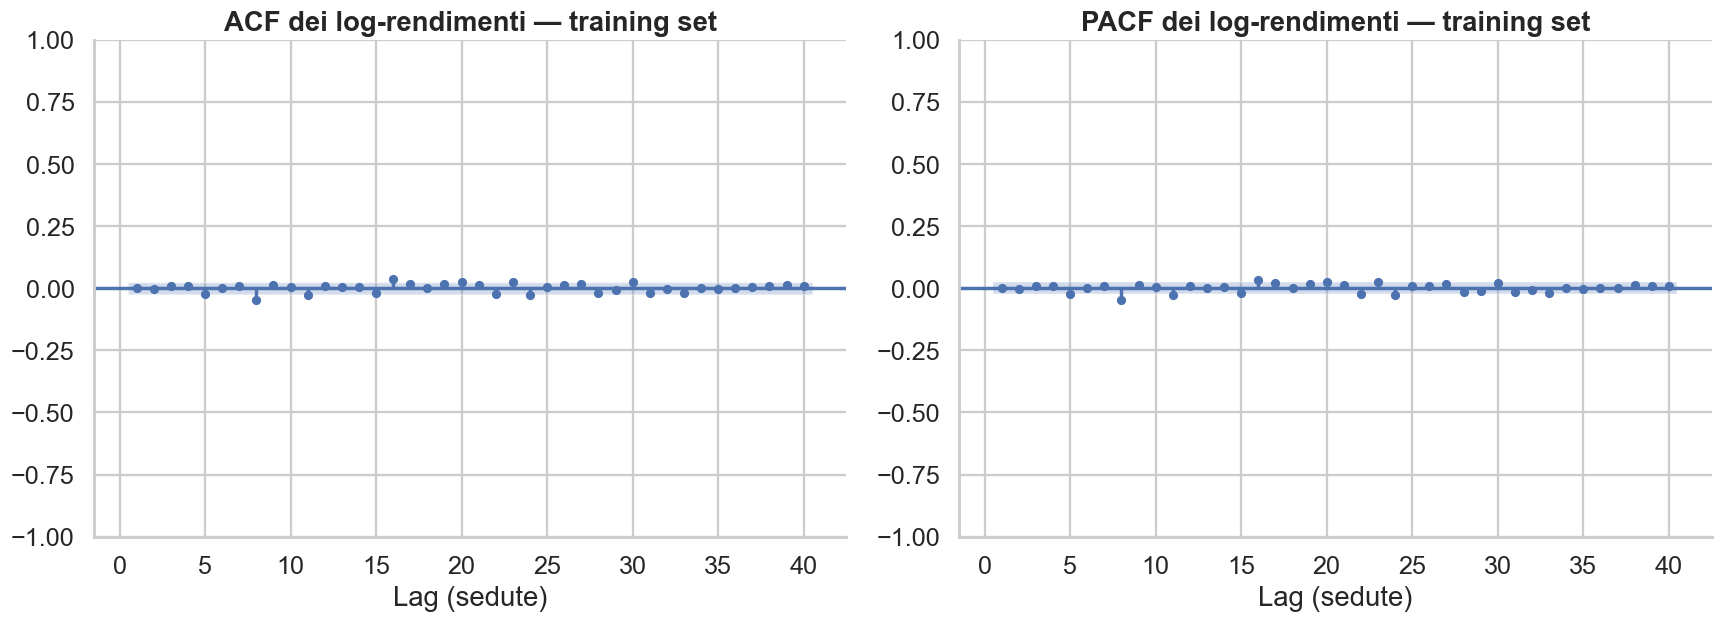

,Lag (sedute),Autocorrelazione
0,5,-0.0224
1,10,0.0051
2,15,-0.0206
3,20,0.0261
4,21,0.0130


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_acf(train_log_return, lags=40, ax=axes[0], zero=False)
plot_pacf(train_log_return, lags=40, ax=axes[1], zero=False, method='ywm')
axes[0].set_title('ACF dei log-rendimenti — training set')
axes[1].set_title('PACF dei log-rendimenti — training set')
for ax in axes:
    ax.set_xlabel('Lag (sedute)')
fig.tight_layout()
fig.savefig(FIG_DIR / '03_acf_pacf.png', dpi=300, bbox_inches='tight')
plt.show()

seasonal_lags = [5, 10, 15, 20, 21]
seasonal_acf_table = pd.DataFrame({
    'Lag (sedute)': seasonal_lags,
    'Autocorrelazione': [train_log_return.autocorr(lag=lag) for lag in seasonal_lags],
})
display(seasonal_acf_table.style.format({'Autocorrelazione': '{:.4f}'}))

## 3. Preparazione della valutazione

La variabile esogena è:

\[
x_t = \log(Volume_{t-1})
\]

Per prevedere il prezzo della seduta `t` viene quindi usato esclusivamente il volume della seduta precedente. Le ultime 30 osservazioni costituiscono il test set.

In [5]:
# Per statsmodels utilizziamo un RangeIndex; le date originali vengono
# conservate separatamente e riapplicate ai risultati grafici.
y_train = train['log_price'].reset_index(drop=True)
X_train = train[['log_volume_lag1']].reset_index(drop=True)
y_test = test['log_price'].reset_index(drop=True)
X_test = test[['log_volume_lag1']].reset_index(drop=True)

print(f'Training: {train.index.min().date()} — {train.index.max().date()} ({len(train):,} sedute)')
print(f'Test:     {test.index.min().date()} — {test.index.max().date()} ({len(test):,} sedute)')

Training: 1999-01-25 — 2024-12-31 (6,527 sedute)
Test:     2025-01-02 — 2025-02-14 (30 sedute)


## 4. Selezione dell'ordine sul solo training set

Le configurazioni candidate vengono confrontate tramite AIC senza utilizzare le osservazioni del test. Per rendere uniforme la stima, ARIMA, ARIMAX e SARIMAX sono tutti stimati attraverso la classe state-space `SARIMAX` di statsmodels, con le stesse impostazioni `enforce_stationarity=False` ed `enforce_invertibility=False`. ARIMA non utilizza variabili esogene; ARIMA e ARIMAX usano `seasonal_order=(0, 0, 0, 0)`. La stessa funzione di stima viene impiegata sia nella selezione sia nella valutazione finale. Una configurazione non convergente viene mostrata nella tabella ma esclusa dalla selezione automatica.

In [6]:
candidate_orders = [(0, 1, 0), (0, 1, 1), (1, 1, 0), (1, 1, 1), (2, 1, 2)]
MAX_ITER = 500

def fit_state_space(endog, order, exog=None, seasonal_order=(0, 0, 0, 0)):
    return sm.tsa.SARIMAX(
        endog,
        exog=exog,
        order=order,
        seasonal_order=seasonal_order,
        enforce_stationarity=False,
        enforce_invertibility=False,
    ).fit(disp=False, maxiter=MAX_ITER)

def has_converged(fit):
    return bool(getattr(fit, 'mle_retvals', {}).get('converged', True))

selection_rows = []
order_lookup = {str(order): order for order in candidate_orders}

for order in candidate_orders:
    arima_fit = fit_state_space(y_train, order=order)
    arimax_fit = fit_state_space(y_train, exog=X_train, order=order)

    selection_rows.append({
        'Ordine': str(order),
        'AIC ARIMA': arima_fit.aic,
        'Convergenza ARIMA': has_converged(arima_fit),
        'AIC ARIMAX': arimax_fit.aic,
        'Convergenza ARIMAX': has_converged(arimax_fit),
    })

aic_table = pd.DataFrame(selection_rows).set_index('Ordine')
display(aic_table.style.format({
    'AIC ARIMA': '{:.2f}',
    'AIC ARIMAX': '{:.2f}',
}).highlight_min(subset=['AIC ARIMA', 'AIC ARIMAX'], color='#c7e9c0'))

valid_arima = aic_table[aic_table['Convergenza ARIMA']]
valid_arimax = aic_table[aic_table['Convergenza ARIMAX']]
if valid_arima.empty or valid_arimax.empty:
    raise RuntimeError('Nessuna configurazione convergente disponibile per la selezione.')

best_arima_order = order_lookup[valid_arima['AIC ARIMA'].idxmin()]
best_arimax_order = order_lookup[valid_arimax['AIC ARIMAX'].idxmin()]
print(f'Miglior ordine ARIMA:   {best_arima_order}')
print(f'Miglior ordine ARIMAX:  {best_arimax_order}')

,AIC ARIMA,Convergenza ARIMA,AIC ARIMAX,Convergenza ARIMAX
Ordine,,,,
"(0, 1, 0)",-24293.50,True,-24292.83,True
"(0, 1, 1)",-24286.78,True,-24286.11,True
"(1, 1, 0)",-24291.50,True,-24290.83,True
"(1, 1, 1)",-24284.33,True,-24283.74,True
"(2, 1, 2)",-24289.50,True,-24298.07,True


Miglior ordine ARIMA:   (0, 1, 0)
Miglior ordine ARIMAX:  (2, 1, 2)


### 4.1 Verifica di una componente stagionale

Le autocorrelazioni dei log-rendimenti del training set ai lag 5, 10, 15, 20 e 21 sono vicine allo zero e non mostrano una successione regolare di picchi. La stagionalità viene comunque verificata con un insieme ristretto di specifiche SARIMAX aventi periodo `s = 5`, interpretato come cinque sedute consecutive e non come una settimana di calendario esatta. Si mantiene `D = 0` per evitare una differenziazione stagionale non supportata dai dati.

Durante questa verifica viene mantenuto fisso il migliore ordine non stagionale selezionato per ARIMAX e vengono modificati soltanto i parametri `(P, D, Q, s)`. Non si tratta quindi di una ricerca completa di tutte le combinazioni tra ordini stagionali e non stagionali. Il caso `(0, 0, 0, 5)` è il riferimento privo di termini stagionali; tra le sole configurazioni effettivamente stagionali e convergenti viene poi scelta quella da utilizzare nel confronto fuori campione.

,AIC,Componente stagionale,Convergenza
Ordine stagionale,,,
"(0, 0, 0, 5)",-24298.07,False,True
"(1, 0, 0, 5)",-24277.57,True,True
"(0, 0, 1, 5)",-24272.86,True,True
"(1, 0, 1, 5)",-24270.25,True,True


Configurazione selezionata tra quelle effettivamente stagionali esaminate: (1, 0, 0, 5)


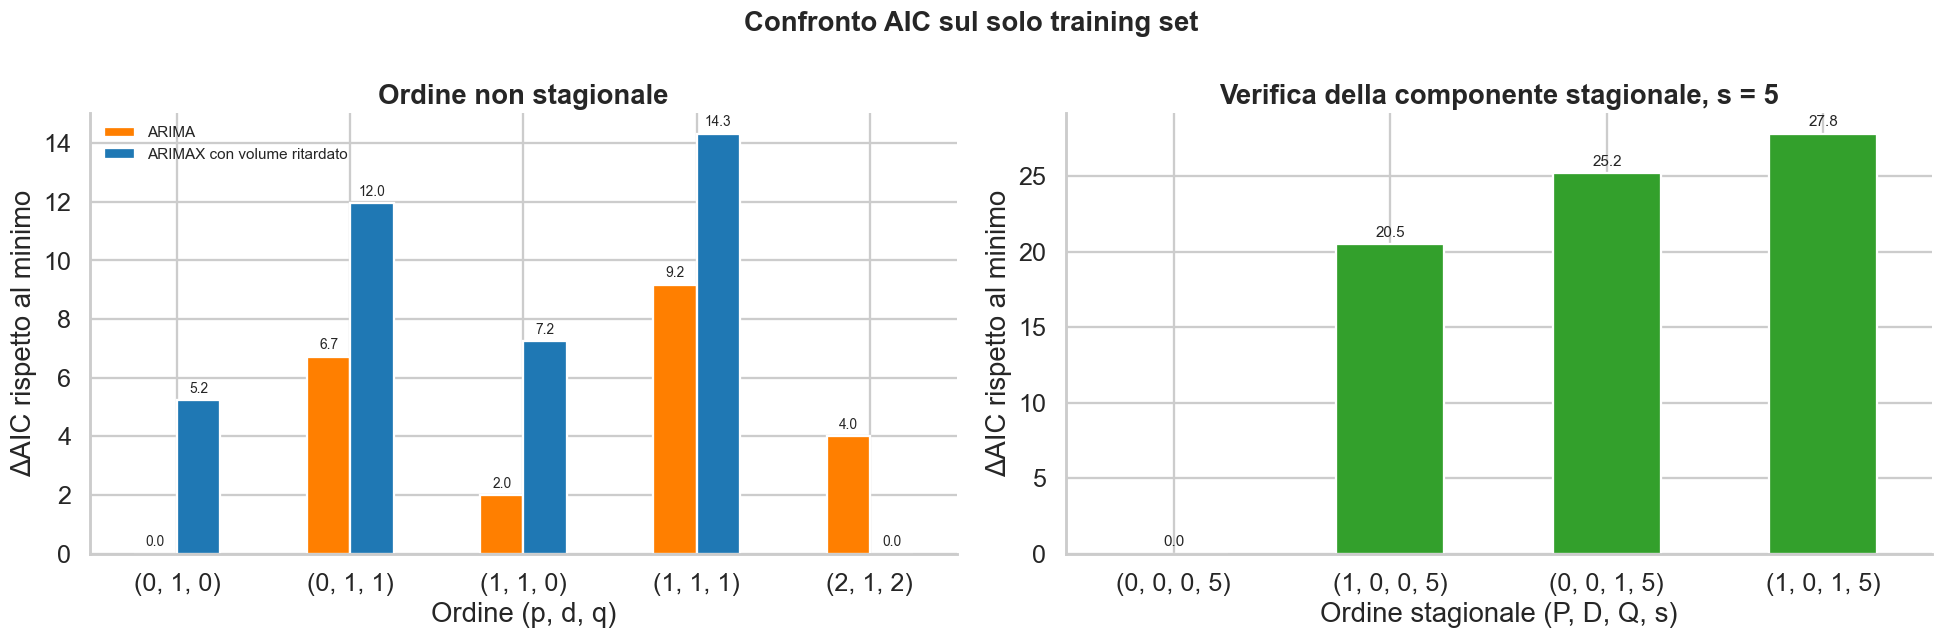

In [7]:
SEASONAL_PERIOD = 5
candidate_seasonal_orders = [
    (0, 0, 0, SEASONAL_PERIOD),
    (1, 0, 0, SEASONAL_PERIOD),
    (0, 0, 1, SEASONAL_PERIOD),
    (1, 0, 1, SEASONAL_PERIOD),
]
seasonal_selection_rows = []

for seasonal_order in candidate_seasonal_orders:
    seasonal_fit = fit_state_space(
        y_train,
        exog=X_train,
        order=best_arimax_order,
        seasonal_order=seasonal_order,
    )
    seasonal_selection_rows.append({
        'Ordine stagionale': str(seasonal_order),
        'AIC': seasonal_fit.aic,
        'Componente stagionale': seasonal_order[:3] != (0, 0, 0),
        'Convergenza': has_converged(seasonal_fit),
    })

seasonal_aic_table = pd.DataFrame(seasonal_selection_rows).set_index('Ordine stagionale')
true_seasonal_rows = seasonal_aic_table[
    seasonal_aic_table['Componente stagionale'] & seasonal_aic_table['Convergenza']
]
if true_seasonal_rows.empty:
    raise RuntimeError('Nessuna configurazione stagionale convergente disponibile.')
best_sarimax_seasonal_order = tuple(
    int(value.strip())
    for value in true_seasonal_rows['AIC'].idxmin().strip('()').split(',')
)

display(seasonal_aic_table.style.format({'AIC': '{:.2f}'}).highlight_min(
    subset=['AIC'], color='#c7e9c0'
))
print(
    'Configurazione selezionata tra quelle effettivamente stagionali esaminate: '
    f'{best_sarimax_seasonal_order}'
)

aic_values = aic_table[['AIC ARIMA', 'AIC ARIMAX']]
aic_delta = aic_values - aic_values.min(axis=0)
seasonal_aic_delta = seasonal_aic_table['AIC'] - seasonal_aic_table['AIC'].min()

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
aic_delta.plot(kind='bar', color=['#ff7f00', '#1f78b4'], ax=axes[0])
axes[0].set_title('Ordine non stagionale')
axes[0].set_xlabel('Ordine (p, d, q)')
axes[0].set_ylabel('ΔAIC rispetto al minimo')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(['ARIMA', 'ARIMAX con volume ritardato'], fontsize=10)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.1f', padding=3, fontsize=9)

seasonal_aic_delta.plot(kind='bar', color='#33a02c', ax=axes[1])
axes[1].set_title('Verifica della componente stagionale, s = 5')
axes[1].set_xlabel('Ordine stagionale (P, D, Q, s)')
axes[1].set_ylabel('ΔAIC rispetto al minimo')
axes[1].tick_params(axis='x', rotation=0)
axes[1].bar_label(axes[1].containers[0], fmt='%.1f', padding=3, fontsize=10)

fig.suptitle('Confronto AIC sul solo training set', fontsize=18, fontweight='bold')
fig.tight_layout()
fig.savefig(FIG_DIR / '04_confronto_aic.png', dpi=300, bbox_inches='tight')
plt.show()

## 5. Previsione giornaliera con aggiornamento progressivo

I modelli vengono stimati sul training set. Per ogni data del test:

1. si effettua una previsione a un passo;
2. si registra la previsione e il relativo intervallo al 95%;
3. si aggiunge l'osservazione reale alla storia;
4. si passa alla seduta successiva.

I parametri restano quelli stimati sul training set, mentre lo stato del modello viene aggiornato con le nuove osservazioni.

In [8]:
arima_results = fit_state_space(y_train, order=best_arima_order)
arimax_results = fit_state_space(
    y_train, exog=X_train, order=best_arimax_order
)
sarimax_results = fit_state_space(
    y_train,
    exog=X_train,
    order=best_arimax_order,
    seasonal_order=best_sarimax_seasonal_order,
)

final_convergence = pd.DataFrame({
    'Modello': ['ARIMA', 'ARIMAX', 'SARIMAX'],
    'Convergenza': [
        has_converged(arima_results),
        has_converged(arimax_results),
        has_converged(sarimax_results),
    ],
})
display(final_convergence)
if not final_convergence['Convergenza'].all():
    raise RuntimeError('Almeno uno dei modelli finali non è convergente.')

# Conserviamo inferenza e diagnostica del modello stimato solo sul training.
arimax_train_results = arimax_results
sarimax_train_results = sarimax_results

arima_pred_log, arimax_pred_log, sarimax_pred_log = [], [], []
arima_lower_log, arima_upper_log = [], []
arimax_lower_log, arimax_upper_log = [], []
sarimax_lower_log, sarimax_upper_log = [], []

for i in range(TEST_SIZE):
    arima_fc = arima_results.get_forecast(steps=1)
    arimax_fc = arimax_results.get_forecast(steps=1, exog=X_test.iloc[[i]])
    sarimax_fc = sarimax_results.get_forecast(steps=1, exog=X_test.iloc[[i]])

    arima_pred_log.append(float(arima_fc.predicted_mean.iloc[0]))
    arimax_pred_log.append(float(arimax_fc.predicted_mean.iloc[0]))
    sarimax_pred_log.append(float(sarimax_fc.predicted_mean.iloc[0]))

    arima_ci = arima_fc.conf_int(alpha=0.05).iloc[0]
    arimax_ci = arimax_fc.conf_int(alpha=0.05).iloc[0]
    sarimax_ci = sarimax_fc.conf_int(alpha=0.05).iloc[0]
    arima_lower_log.append(float(arima_ci.iloc[0]))
    arima_upper_log.append(float(arima_ci.iloc[1]))
    arimax_lower_log.append(float(arimax_ci.iloc[0]))
    arimax_upper_log.append(float(arimax_ci.iloc[1]))
    sarimax_lower_log.append(float(sarimax_ci.iloc[0]))
    sarimax_upper_log.append(float(sarimax_ci.iloc[1]))

    next_index = len(arima_results.model.endog)
    observed_y = pd.Series([y_test.iloc[i]], index=[next_index], name='log_price')
    observed_x = pd.DataFrame(
        {'log_volume_lag1': [X_test.iloc[i, 0]]},
        index=[next_index],
    )

    arima_results = arima_results.append(observed_y, refit=False)
    arimax_results = arimax_results.append(observed_y, exog=observed_x, refit=False)
    sarimax_results = sarimax_results.append(observed_y, exog=observed_x, refit=False)

forecast_df = pd.DataFrame(index=test_dates)
forecast_df['Reale'] = np.exp(y_test.to_numpy())
forecast_df['Naive'] = np.r_[np.exp(y_train.iloc[-1]), forecast_df['Reale'].iloc[:-1].to_numpy()]
forecast_df['ARIMA'] = np.exp(arima_pred_log)
forecast_df['ARIMAX'] = np.exp(arimax_pred_log)
forecast_df['SARIMAX'] = np.exp(sarimax_pred_log)
forecast_df['ARIMA_lower'] = np.exp(arima_lower_log)
forecast_df['ARIMA_upper'] = np.exp(arima_upper_log)
forecast_df['ARIMAX_lower'] = np.exp(arimax_lower_log)
forecast_df['ARIMAX_upper'] = np.exp(arimax_upper_log)
forecast_df['SARIMAX_lower'] = np.exp(sarimax_lower_log)
forecast_df['SARIMAX_upper'] = np.exp(sarimax_upper_log)

def regression_metrics(actual, predicted):
    return {
        'MAE ($)': mean_absolute_error(actual, predicted),
        'RMSE ($)': np.sqrt(mean_squared_error(actual, predicted)),
        'MAPE (%)': np.mean(np.abs((actual - predicted) / actual)) * 100,
    }

metrics_table = pd.DataFrame({
    model: regression_metrics(forecast_df['Reale'], forecast_df[model])
    for model in ['Naive', 'ARIMA', 'ARIMAX', 'SARIMAX']
}).T

display(metrics_table.style.format('{:.4f}').highlight_min(color='#c7e9c0', axis=0))

arimax_volume_coef = arimax_train_results.params['log_volume_lag1']
arimax_volume_pvalue = arimax_train_results.pvalues['log_volume_lag1']
sarimax_volume_coef = sarimax_train_results.params['log_volume_lag1']
sarimax_volume_pvalue = sarimax_train_results.pvalues['log_volume_lag1']
print(f'Coefficiente volume ARIMAX: {arimax_volume_coef:.6f} (p-value {arimax_volume_pvalue:.4f})')
print(f'Coefficiente volume SARIMAX: {sarimax_volume_coef:.6f} (p-value {sarimax_volume_pvalue:.4f})')

,Modello,Convergenza
0,ARIMA,True
1,ARIMAX,True
2,SARIMAX,True


,MAE ($),RMSE ($),MAPE (%)
Naive,4.4753,6.2464,3.4209
ARIMA,4.4753,6.2464,3.4209
ARIMAX,4.4901,6.2535,3.4322
SARIMAX,4.5261,6.2816,3.4612


Coefficiente volume ARIMAX: 0.001675 (p-value 0.1196)
Coefficiente volume SARIMAX: 0.001499 (p-value 0.1639)


## 6. Grafici delle previsioni

Le previsioni sono mostrate in pannelli separati e con la stessa scala verticale. Le linee sovrapposte risulterebbero difficili da distinguere perché i modelli producono valori quasi coincidenti. Un pannello distinto mostra quindi gli scarti di ARIMA, ARIMAX e SARIMAX rispetto alla baseline naïve, rendendo visibili anche differenze molto piccole senza modificare la scala dei prezzi.


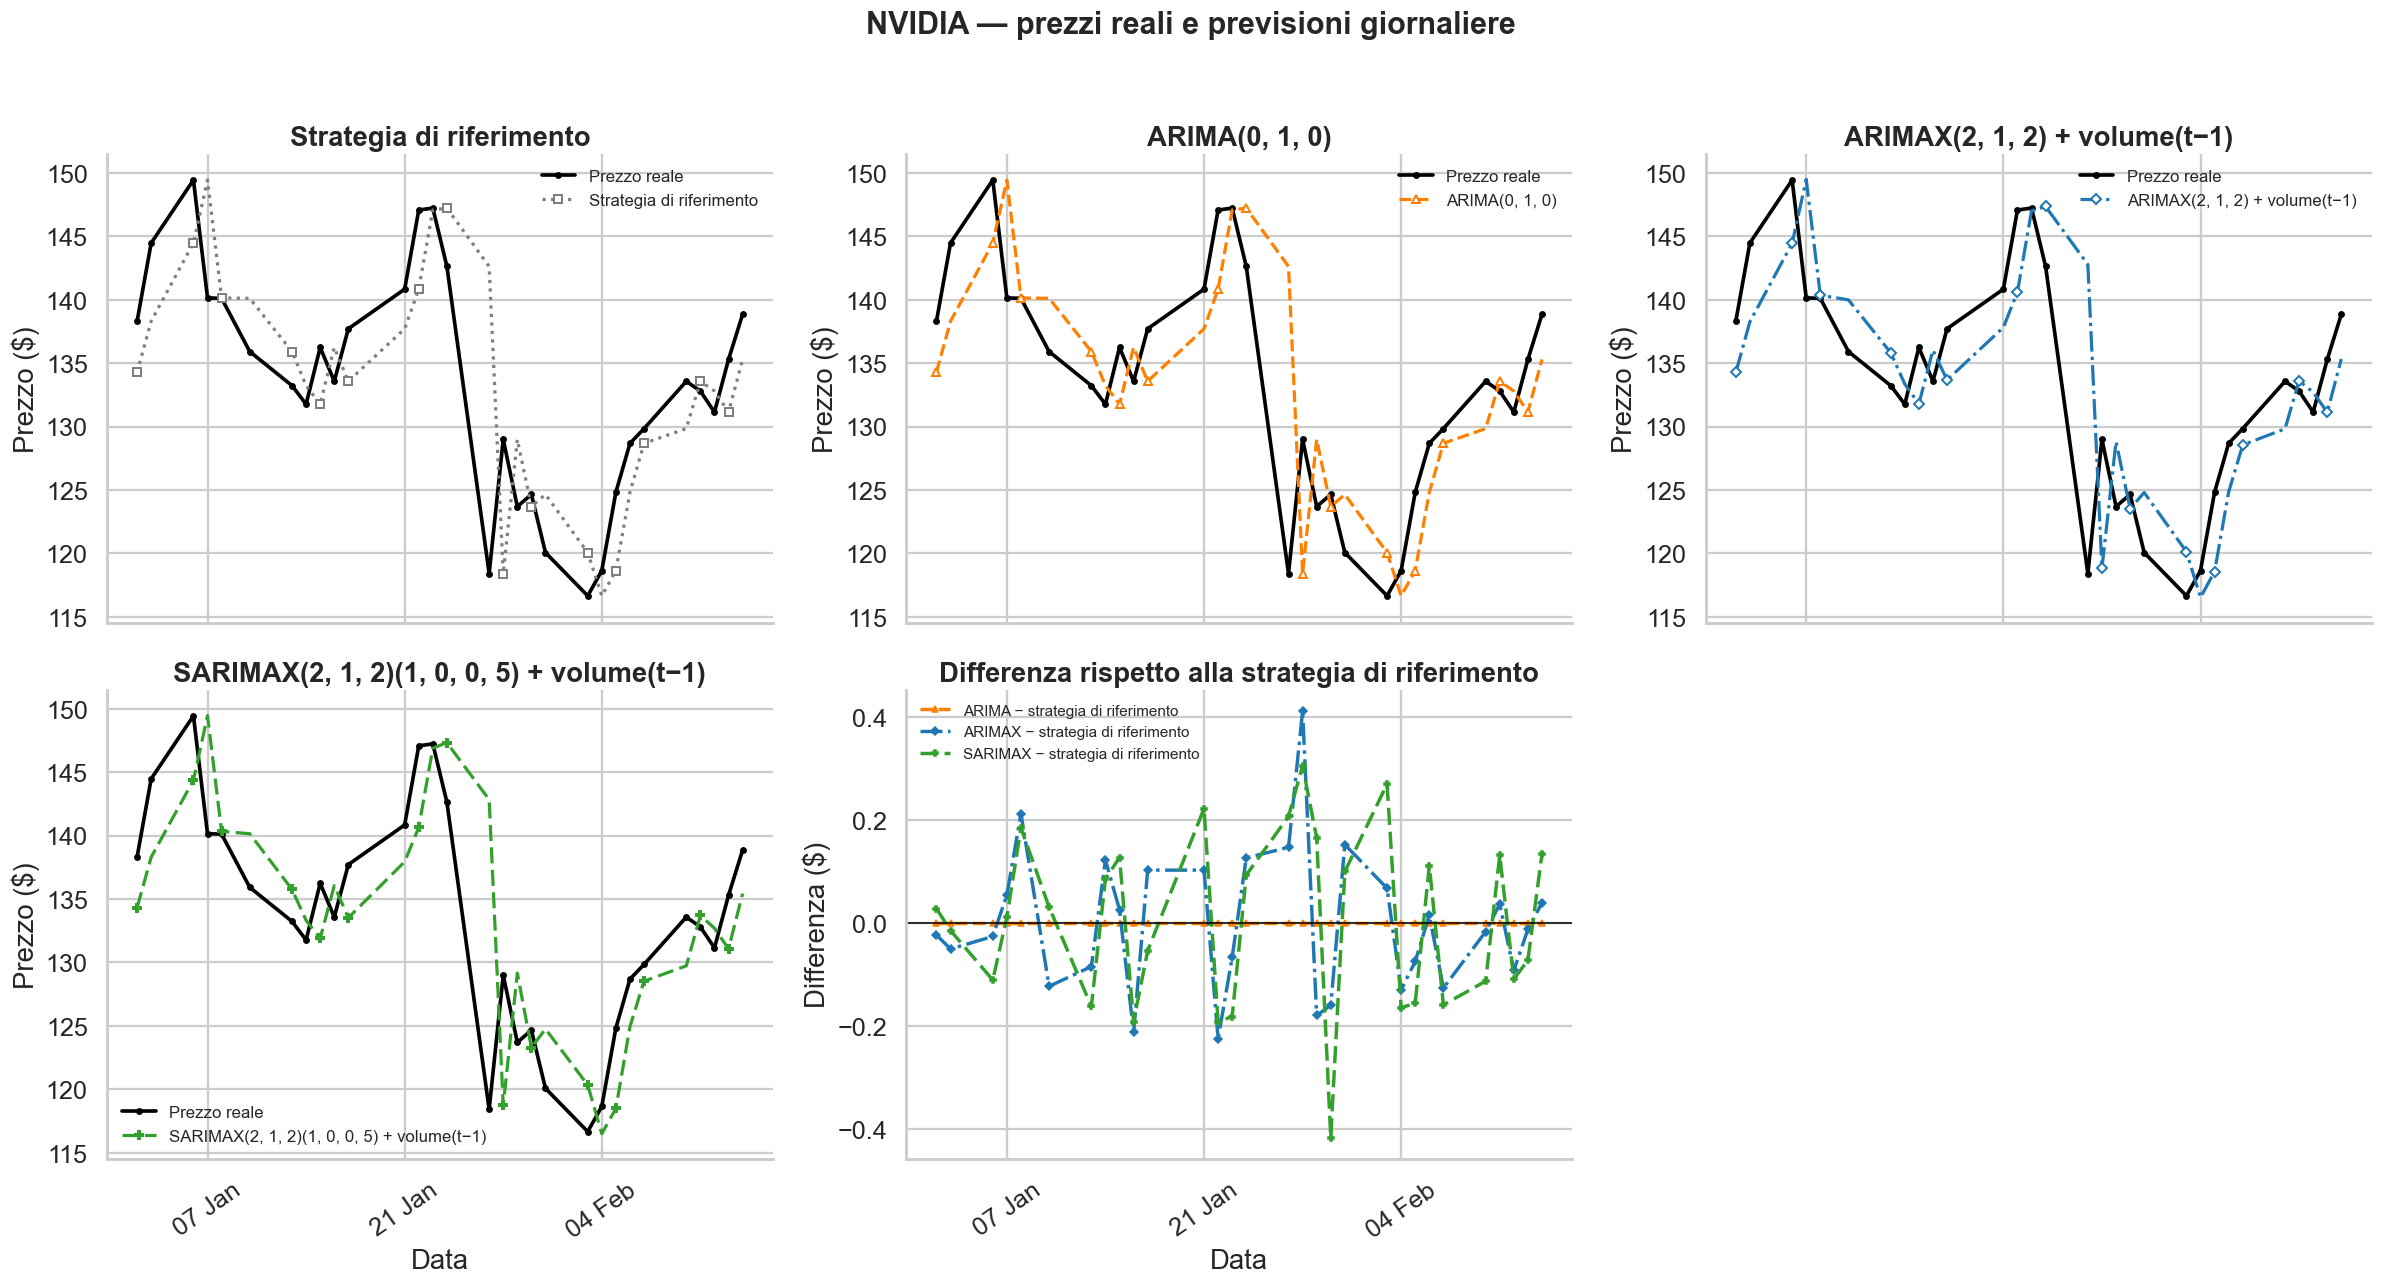

,Scarto medio assoluto dalla strategia di riferimento ($),Scarto massimo assoluto dalla strategia di riferimento ($)
ARIMA,0.0000,0.0000
ARIMAX,0.1073,0.4109
SARIMAX,0.1434,0.4168


In [9]:
model_panels = [
    ('Naive', 'Strategia di riferimento', '#7f7f7f', ':', 's'),
    ('ARIMA', f'ARIMA{best_arima_order}', '#ff7f00', '--', '^'),
    (
        'ARIMAX',
        f'ARIMAX{best_arimax_order} + volume(t−1)',
        '#1f78b4',
        '-.',
        'D',
    ),
    (
        'SARIMAX',
        f'SARIMAX{best_arimax_order}{best_sarimax_seasonal_order} + volume(t−1)',
        '#33a02c',
        (0, (5, 2)),
        'P',
    ),
]

price_min = forecast_df[['Reale', 'Naive', 'ARIMA', 'ARIMAX', 'SARIMAX']].min().min()
price_max = forecast_df[['Reale', 'Naive', 'ARIMA', 'ARIMAX', 'SARIMAX']].max().max()
price_margin = (price_max - price_min) * 0.06

fig, axes = plt.subplots(2, 3, figsize=(22, 12), sharex=True)
axes = axes.ravel()

for ax, (model, label, color, linestyle, marker) in zip(axes[:4], model_panels):
    ax.plot(
        forecast_df.index,
        forecast_df['Reale'],
        color='black',
        linewidth=2.4,
        marker='o',
        markersize=3.5,
        label='Prezzo reale',
        zorder=3,
    )
    ax.plot(
        forecast_df.index,
        forecast_df[model],
        color=color,
        linewidth=2.1,
        linestyle=linestyle,
        marker=marker,
        markevery=2,
        markersize=5,
        markerfacecolor='white',
        markeredgewidth=1.3,
        label=label,
        zorder=4,
    )
    ax.set_title(label)
    ax.set_ylabel('Prezzo ($)')
    ax.set_ylim(price_min - price_margin, price_max + price_margin)
    ax.legend(fontsize=11)

difference_arima_naive = forecast_df['ARIMA'] - forecast_df['Naive']
difference_arimax_naive = forecast_df['ARIMAX'] - forecast_df['Naive']
difference_sarimax_naive = forecast_df['SARIMAX'] - forecast_df['Naive']

axes[4].plot(
    forecast_df.index,
    difference_arima_naive,
    color='#ff7f00',
    linestyle='--',
    marker='^',
    markersize=4,
    label='ARIMA − strategia di riferimento',
)
axes[4].plot(
    forecast_df.index,
    difference_arimax_naive,
    color='#1f78b4',
    linestyle='-.',
    marker='D',
    markersize=3.5,
    label='ARIMAX − strategia di riferimento',
)
axes[4].plot(
    forecast_df.index,
    difference_sarimax_naive,
    color='#33a02c',
    linestyle=(0, (5, 2)),
    marker='P',
    markersize=3.5,
    label='SARIMAX − strategia di riferimento',
)
axes[4].axhline(0, color='black', linewidth=1)
axes[4].set_title('Differenza rispetto alla strategia di riferimento')
axes[4].set_ylabel('Differenza ($)')
axes[4].legend(fontsize=10)
axes[5].axis('off')

for ax in axes:
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    ax.tick_params(axis='x', rotation=35)

for ax in axes[3:5]:
    ax.set_xlabel('Data')
fig.suptitle(
    'NVIDIA — prezzi reali e previsioni giornaliere',
    fontsize=20,
    fontweight='bold',
)
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(FIG_DIR / '05_confronto_previsioni.png', dpi=300, bbox_inches='tight')
plt.show()

difference_table = pd.DataFrame({
    'Scarto medio assoluto dalla strategia di riferimento ($)': [
        difference_arima_naive.abs().mean(),
        difference_arimax_naive.abs().mean(),
        difference_sarimax_naive.abs().mean(),
    ],
    'Scarto massimo assoluto dalla strategia di riferimento ($)': [
        difference_arima_naive.abs().max(),
        difference_arimax_naive.abs().max(),
        difference_sarimax_naive.abs().max(),
    ],
}, index=['ARIMA', 'ARIMAX', 'SARIMAX'])

display(difference_table.style.format('{:.4f}'))


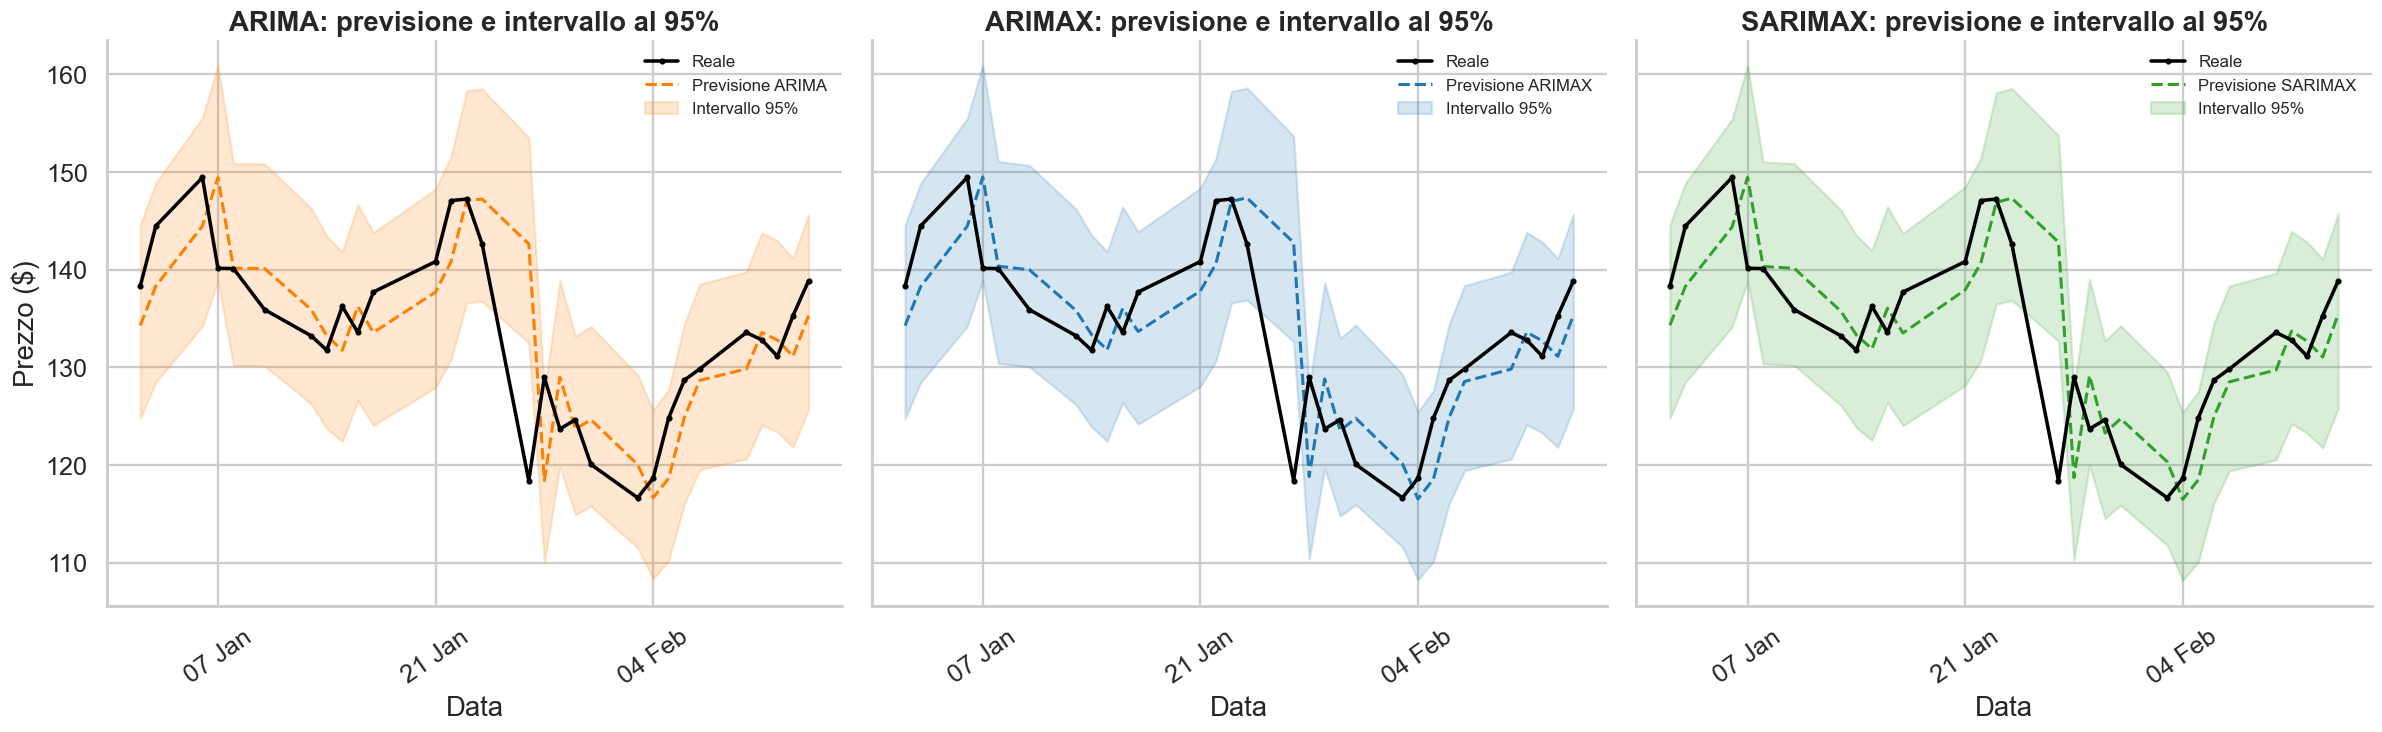

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(22, 7), sharey=True)

for ax, model, color, lower, upper in [
    (axes[0], 'ARIMA', '#ff7f00', 'ARIMA_lower', 'ARIMA_upper'),
    (axes[1], 'ARIMAX', '#1f78b4', 'ARIMAX_lower', 'ARIMAX_upper'),
    (axes[2], 'SARIMAX', '#33a02c', 'SARIMAX_lower', 'SARIMAX_upper'),
]:
    ax.plot(forecast_df.index, forecast_df['Reale'], color='black', linewidth=2.3,
            marker='o', markersize=3, label='Reale', zorder=4)
    ax.plot(forecast_df.index, forecast_df[model], color=color, linewidth=2,
            linestyle='--', label=f'Previsione {model}')
    ax.fill_between(forecast_df.index, forecast_df[lower], forecast_df[upper],
                    color=color, alpha=0.18, label='Intervallo 95%')
    ax.set_title(f'{model}: previsione e intervallo al 95%')
    ax.set_xlabel('Data')
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    ax.tick_params(axis='x', rotation=35)
    ax.legend(fontsize=11)

axes[0].set_ylabel('Prezzo ($)')
fig.tight_layout()
fig.savefig(FIG_DIR / '06_intervalli_previsione.png', dpi=300, bbox_inches='tight')
plt.show()

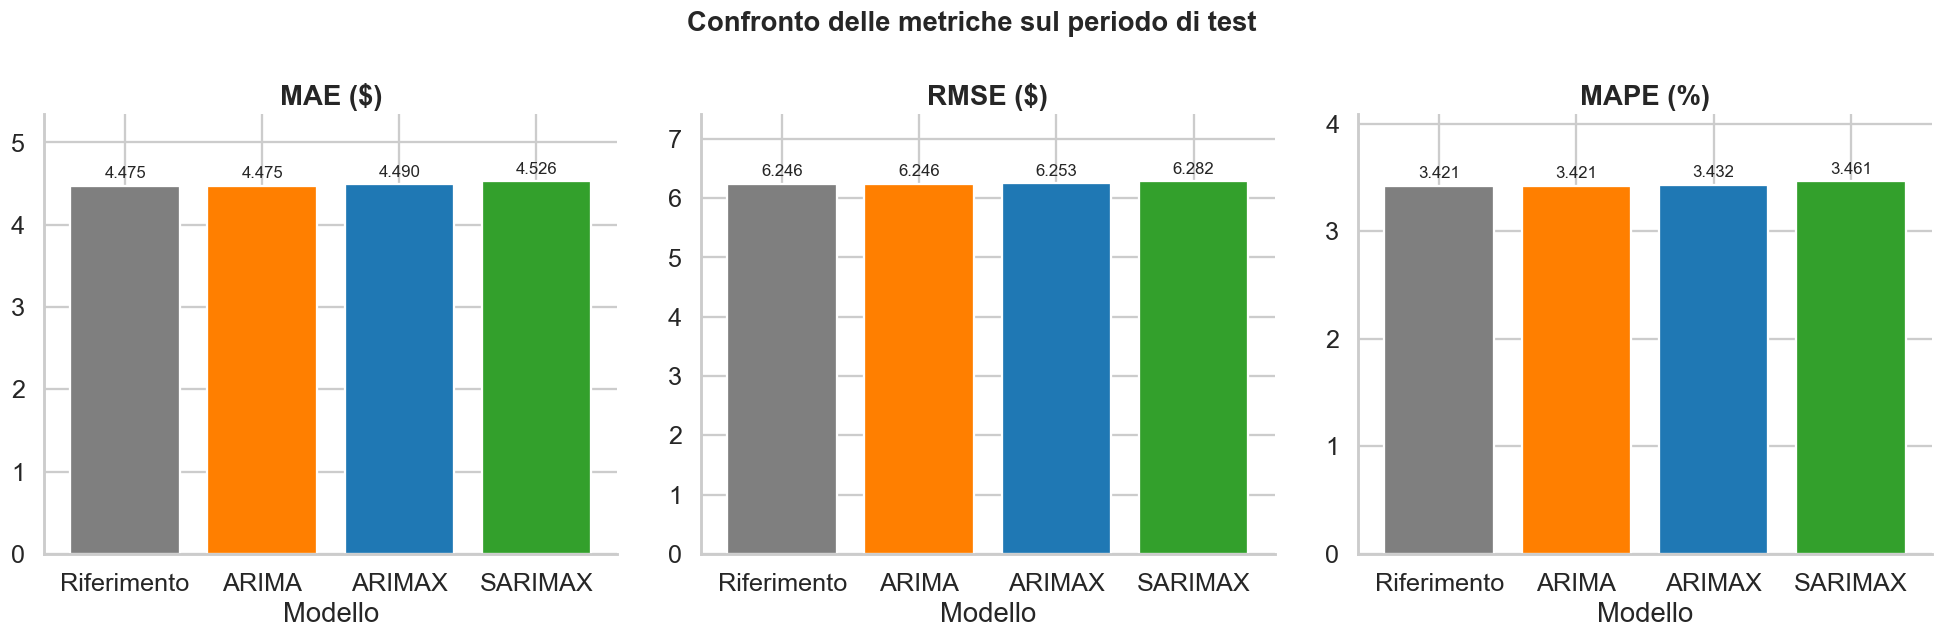

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
colors = ['#7f7f7f', '#ff7f00', '#1f78b4', '#33a02c']
metrics_for_plot = metrics_table.rename(index={'Naive': 'Riferimento'})

for ax, metric in zip(axes, metrics_for_plot.columns):
    bars = ax.bar(metrics_for_plot.index, metrics_for_plot[metric], color=colors)
    ax.set_title(metric)
    ax.set_xlabel('Modello')
    ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=11)
    ax.set_ylim(0, metrics_for_plot[metric].max() * 1.18)

fig.suptitle('Confronto delle metriche sul periodo di test', fontsize=18, fontweight='bold')
fig.tight_layout()
fig.savefig(FIG_DIR / '07_confronto_metriche.png', dpi=300, bbox_inches='tight')
plt.show()

## 7. Diagnostica ARIMAX e SARIMAX

La diagnostica viene calcolata sui residui dei modelli stimati esclusivamente sul training set. Oltre ai grafici viene riportato il test di Ljung–Box per verificare l'autocorrelazione residua, includendo i lag collegati al periodo stagionale di cinque sedute.

Test di Ljung–Box — ARIMAX


,lb_stat,lb_pvalue
5,4.1088,0.5339
10,11.7630,0.3012
20,27.1783,0.1303


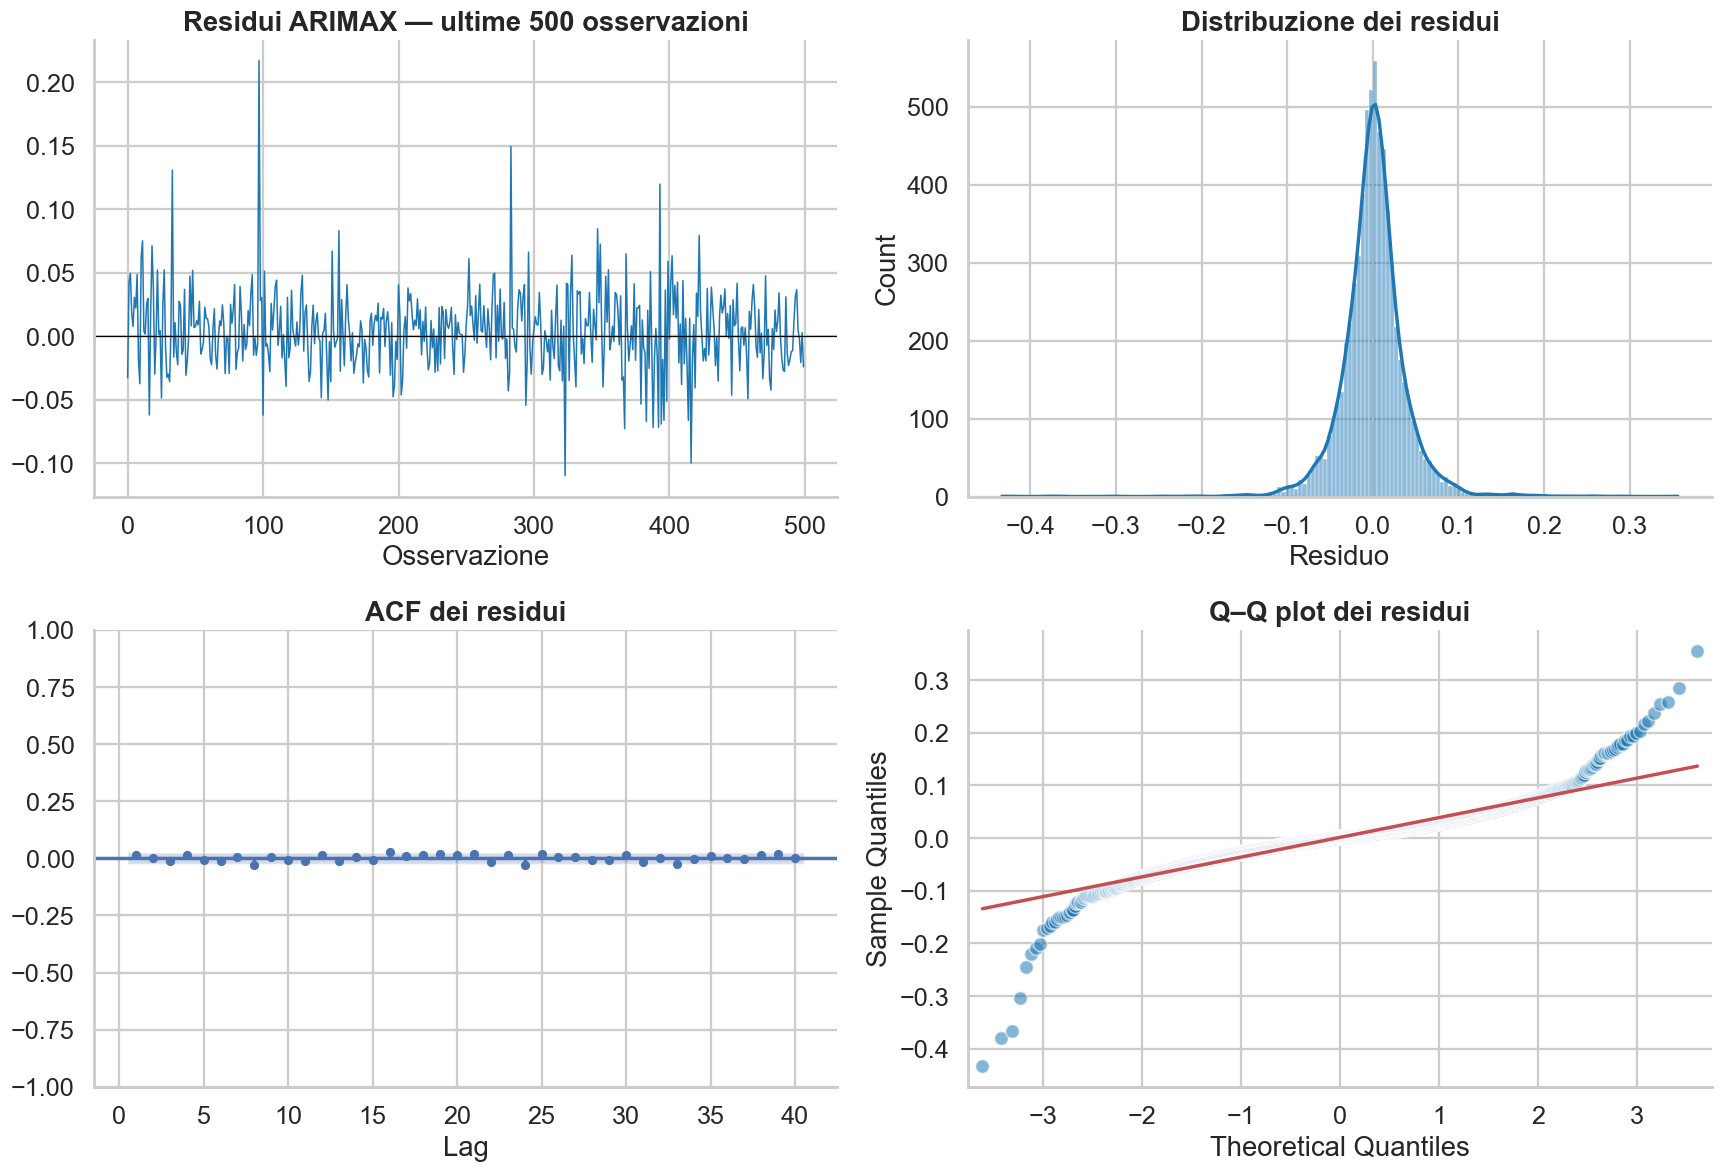

Test di Ljung–Box — SARIMAX stagionale


,lb_stat,lb_pvalue
5,2.9924,0.7012
10,10.9032,0.3651
20,27.5746,0.1199


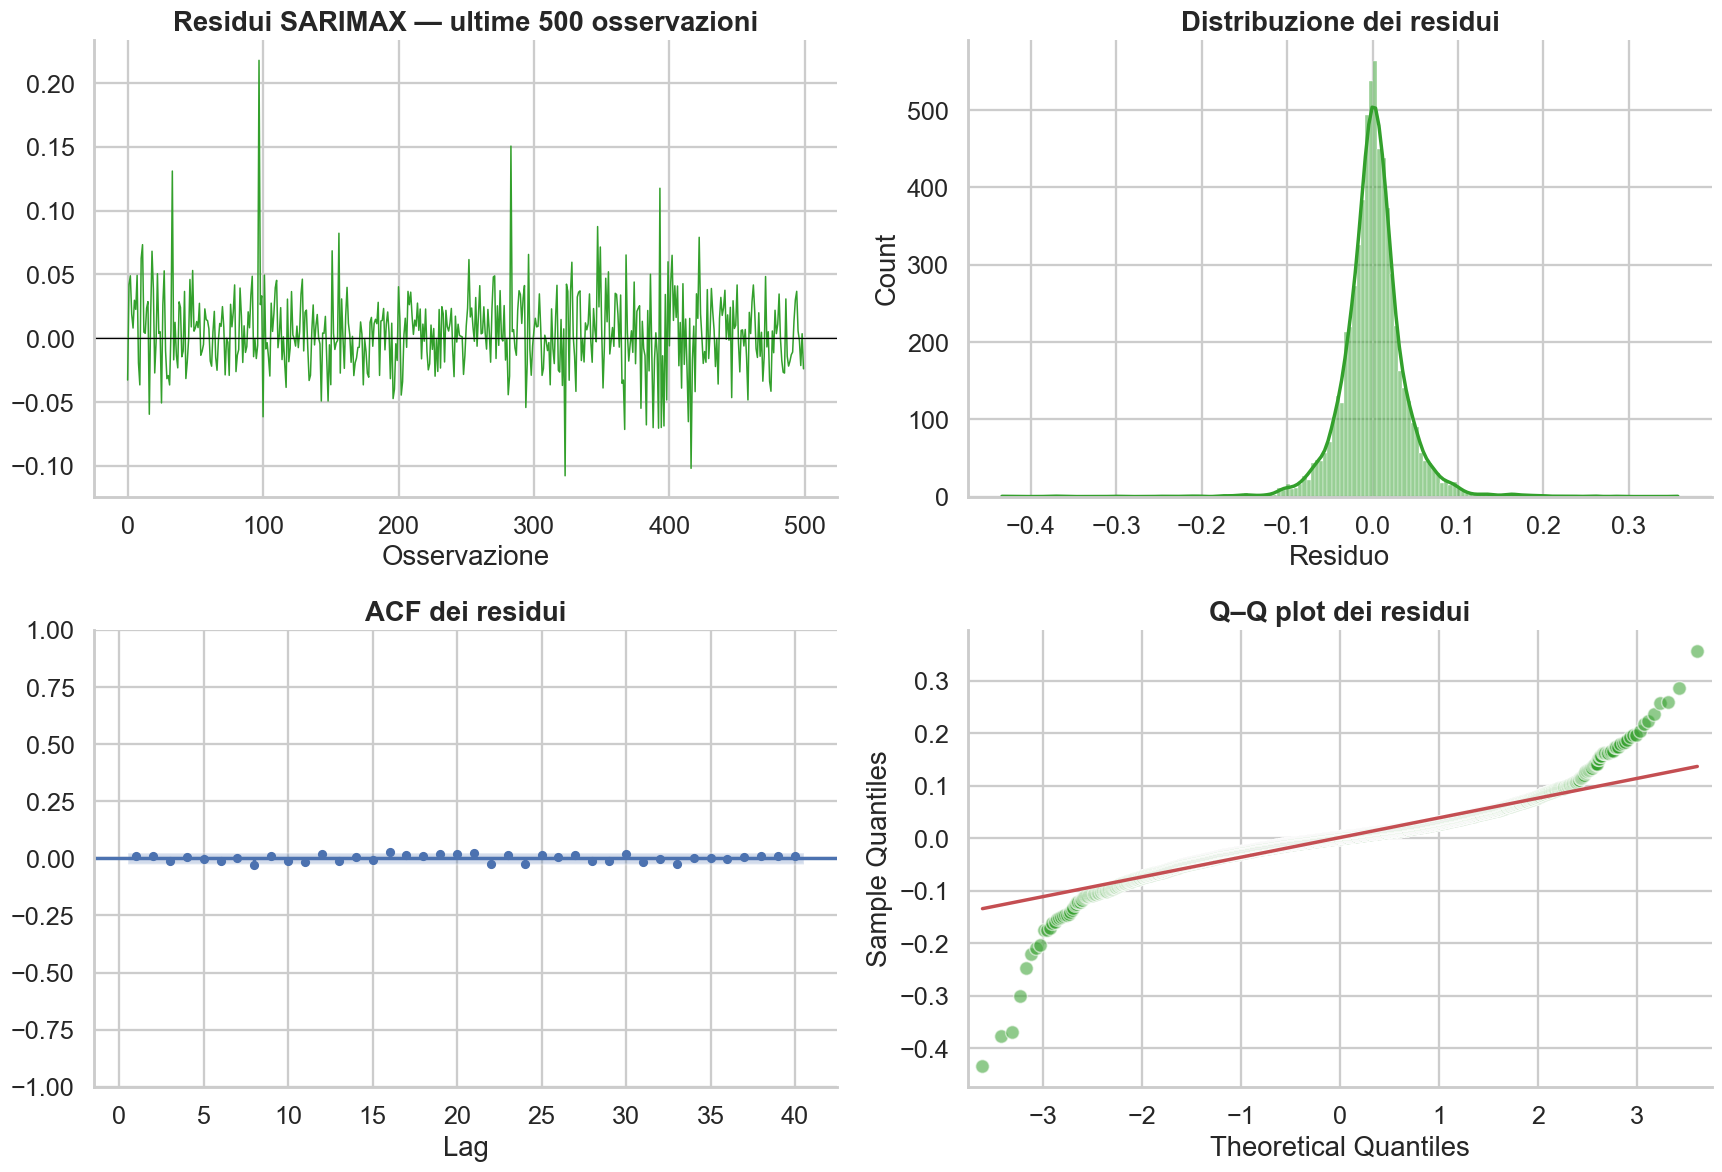

In [12]:
# Escludiamo le osservazioni iniziali usate per l'inizializzazione
# dello state-space model: non sono residui ordinari e deformerebbero
# istogramma e Q–Q plot.
arimax_burn = max(int(arimax_train_results.loglikelihood_burn), best_arimax_order[1])
arimax_residuals = pd.Series(arimax_train_results.resid).iloc[arimax_burn:].dropna()
arimax_ljung_box = sm.stats.acorr_ljungbox(
    arimax_residuals, lags=[5, 10, 20], return_df=True
)
print('Test di Ljung–Box — ARIMAX')
display(arimax_ljung_box.style.format('{:.4f}'))

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

axes[0, 0].plot(arimax_residuals.iloc[-500:].to_numpy(), color='#1f78b4', linewidth=1)
axes[0, 0].axhline(0, color='black', linewidth=0.8)
axes[0, 0].set_title('Residui ARIMAX — ultime 500 osservazioni')
axes[0, 0].set_xlabel('Osservazione')

sns.histplot(arimax_residuals, kde=True, ax=axes[0, 1], color='#1f78b4')
axes[0, 1].set_title('Distribuzione dei residui')
axes[0, 1].set_xlabel('Residuo')

plot_acf(arimax_residuals, lags=40, zero=False, ax=axes[1, 0])
axes[1, 0].set_title('ACF dei residui')
axes[1, 0].set_xlabel('Lag')

sm.qqplot(arimax_residuals, line='s', ax=axes[1, 1], markerfacecolor='#1f78b4',
          markeredgecolor='white', alpha=0.55)
axes[1, 1].set_title('Q–Q plot dei residui')

fig.tight_layout()
fig.savefig(FIG_DIR / '08_diagnostica_arimax.png', dpi=300, bbox_inches='tight')
plt.show()

sarimax_burn = max(int(sarimax_train_results.loglikelihood_burn), best_arimax_order[1])
sarimax_residuals = pd.Series(sarimax_train_results.resid).iloc[sarimax_burn:].dropna()
sarimax_ljung_box = sm.stats.acorr_ljungbox(
    sarimax_residuals, lags=[5, 10, 20], return_df=True
)
print('Test di Ljung–Box — SARIMAX stagionale')
display(sarimax_ljung_box.style.format('{:.4f}'))

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
axes[0, 0].plot(sarimax_residuals.iloc[-500:].to_numpy(), color='#33a02c', linewidth=1)
axes[0, 0].axhline(0, color='black', linewidth=0.8)
axes[0, 0].set_title('Residui SARIMAX — ultime 500 osservazioni')
axes[0, 0].set_xlabel('Osservazione')

sns.histplot(sarimax_residuals, kde=True, ax=axes[0, 1], color='#33a02c')
axes[0, 1].set_title('Distribuzione dei residui')
axes[0, 1].set_xlabel('Residuo')

plot_acf(sarimax_residuals, lags=40, zero=False, ax=axes[1, 0])
axes[1, 0].set_title('ACF dei residui')
axes[1, 0].set_xlabel('Lag')

sm.qqplot(sarimax_residuals, line='s', ax=axes[1, 1], markerfacecolor='#33a02c',
          markeredgecolor='white', alpha=0.55)
axes[1, 1].set_title('Q–Q plot dei residui')

fig.tight_layout()
fig.savefig(FIG_DIR / '09_diagnostica_sarimax.png', dpi=300, bbox_inches='tight')
plt.show()

## 8. Interpretazione

La significatività del volume e l'entità del miglioramento devono essere valutate congiuntamente:

- un RMSE leggermente più basso non implica necessariamente un vantaggio sostanziale;
- un p-value elevato del coefficiente del volume indica che non emerge un effetto statisticamente significativo;
- la selezione tramite AIC non garantisce che il modello superi una baseline semplice fuori campione.

Il modello non stagionale con volume viene denominato ARIMAX, anche se è stimato attraverso la classe `SARIMAX` di statsmodels. Le autocorrelazioni dei log-rendimenti del training set non mostrano una periodicità regolare ai multipli di cinque; inoltre il riferimento non stagionale ottiene un AIC inferiore rispetto alle specifiche SARIMAX effettivamente stagionali. Il SARIMAX viene comunque mantenuto nel confronto per documentare l'esperimento svolto, non perché la stagionalità risulti confermata.

Il test di Ljung–Box non rileva autocorrelazione residua significativa: per ARIMAX i p-value ai lag 5, 10 e 20 sono rispettivamente 0,5339, 0,3012 e 0,1303; per SARIMAX sono 0,7012, 0,3651 e 0,1199. Tutti rimangono superiori alla soglia del 5%. Questo risultato riguarda l'autocorrelazione, non la normalità: gli istogrammi molto concentrati e le deviazioni nelle code dei Q–Q plot indicano che la distribuzione dei residui non è ben approssimata da una normale.

Con la stima uniforme ARIMA seleziona l'ordine `(0, 1, 0)` e produce le stesse metriche della baseline naïve. ARIMAX e SARIMAX sono stati applicati senza leakage, ma né il volume ritardato né la componente stagionale aggiungono un potere predittivo robusto nel periodo analizzato.

In [13]:
arimax_rmse_increase = metrics_table.loc['ARIMAX', 'RMSE ($)'] - metrics_table.loc['ARIMA', 'RMSE ($)']
sarimax_rmse_increase = metrics_table.loc['SARIMAX', 'RMSE ($)'] - metrics_table.loc['ARIMAX', 'RMSE ($)']
minimum_rmse = metrics_table['RMSE ($)'].min()
best_models = metrics_table.index[
    np.isclose(metrics_table['RMSE ($)'], minimum_rmse, atol=1e-10)
].tolist()

print('CONCLUSIONE DELLA VALUTAZIONE')
print('-' * 60)
print(f"RMSE Naïve:   ${metrics_table.loc['Naive', 'RMSE ($)']:.4f}")
print(f"RMSE ARIMA:   ${metrics_table.loc['ARIMA', 'RMSE ($)']:.4f}")
print(f"RMSE ARIMAX:  ${metrics_table.loc['ARIMAX', 'RMSE ($)']:.4f}")
print(f"RMSE SARIMAX: ${metrics_table.loc['SARIMAX', 'RMSE ($)']:.4f}")
print(f'Aumento RMSE ARIMAX rispetto ad ARIMA:  ${arimax_rmse_increase:.4f}')
print(f'Aumento RMSE SARIMAX rispetto ad ARIMAX: ${sarimax_rmse_increase:.4f}')
print(f'P-value volume ARIMAX:  {arimax_volume_pvalue:.4f}')
print(f'P-value volume SARIMAX: {sarimax_volume_pvalue:.4f}')
print(f"Migliori modelli per RMSE: {', '.join(best_models)}")

print(
    "ARIMAX peggiora leggermente l'RMSE rispetto ad ARIMA e non supera la baseline naïve; "
    'il coefficiente del volume non è significativo.'
)
print(
    'Il SARIMAX stagionale non migliora ARIMAX: la componente stagionale '
    'non apporta un vantaggio predittivo nel test.'
)

CONCLUSIONE DELLA VALUTAZIONE
------------------------------------------------------------
RMSE Naïve:   $6.2464
RMSE ARIMA:   $6.2464
RMSE ARIMAX:  $6.2535
RMSE SARIMAX: $6.2816
Aumento RMSE ARIMAX rispetto ad ARIMA:  $0.0071
Aumento RMSE SARIMAX rispetto ad ARIMAX: $0.0281
P-value volume ARIMAX:  0.1196
P-value volume SARIMAX: 0.1639
Migliori modelli per RMSE: Naive, ARIMA
ARIMAX peggiora leggermente l'RMSE rispetto ad ARIMA e non supera la baseline naïve; il coefficiente del volume non è significativo.
Il SARIMAX stagionale non migliora ARIMAX: la componente stagionale non apporta un vantaggio predittivo nel test.
